# Exploratory Data Analysis of House Prices

## Introduction

Exploratory Data Analysis (EDA) is the process of
analysing and understanding data using statistics
and visualisations.

## Objective
To analyse house prices using Python and understand
which factors affect house sale prices.

## Dataset
House Prices: Advanced Regression Technique for Housing Dataset from Kaggle.

The dataset contains 1460 rows and 81 columns.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!



## 1. Dataset Loading and First Look

In this section, we load the dataset and check its
structure, number of rows, columns, data types,and missing values.


#### Loading the Dataset

In [2]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### Dataset information

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

#### Checking the missing values

In [4]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print("Missing Values:")
print(missing)

print("\nTotal Columns with Missing Vlaues:",len(missing))

Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

Total Columns with Missing Vlaues: 19


### Observation

The dataset contains 1460 rows and 81 columns.
It includes numerical and categorical variables.

Some columns contain missing values.
These values must be checked before further analysis.



## 2. Classification of Variables

Variables are classified into three main types:

1. Numerical Variables
2. Categorical Variables
3. Ordinal Variables

Numerical variables contain numbers.
Categorical variables represent groups or categories.
Ordinal variables have a meaningful order.


In [5]:

numeric_cols = df.select_dtypes(
    include=np.number
).columns

categorical_cols = df.select_dtypes(
    include=["object","str"] 
).columns

print("Numerical Columns:")
print(list(numeric_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

print("\nTotal Numerical:", len(numeric_cols))
print("Total Categorical:", len(categorical_cols))


Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Fireplac

#### Ordinal variables

In [6]:

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(
        df[col],
        categories=order,
        ordered=True
    )

print("Ordinal variables classified successfully!")

df[["ExterQual", "KitchenQual"]].head()


Ordinal variables classified successfully!


,ExterQual,KitchenQual
0,Gd,Gd
1,TA,TA
2,Gd,Gd
3,TA,Gd
4,Gd,Gd



### Observation

Numerical variables contain measurable values.
Categorical variables represent different groups.

ExterQual and KitchenQual are ordinal variables.
OverallQual is also ordinal because it represents
house quality on a scale from 1 to 10.



## 3. Descriptive Statistics

Descriptive statistics help us understand the
main characteristics of numerical data.

We calculate:

- Mean
- Median
- Mode
- Standard Deviation
- Variance
- Range
- Interquartile Range (IQR)
- Skewness
- Kurtosis


In [7]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


#### Statistical calculations

In [8]:

columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in columns:

    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())

    print("Range:", df[col].max() - df[col].min())

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    print("IQR:", Q3 - Q1)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())



Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288662
Variance: 6311111264.297448
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232025
Variance: 276129.63336259587
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.26493237915
Variance: 99625649.65034176
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033



### Interpretation

Mean represents the average value.
Median represents the middle value.
Mode represents the most frequent value.

Standard deviation and variance measure data spread.
Range shows the difference between maximum and minimum.
IQR measures the spread of the middle 50% of data.

Skewness measures the asymmetry of data.
Kurtosis measures the heaviness of distribution tails.

If the mean is greater than the median, the data
may be right-skewed.



## 4. Distribution Analysis

Distribution analysis helps us understand how data
values are spread across the dataset.

In this section, we use:

1. Histogram
2. KDE Plot
3. Boxplot
4. Log Transformation
5. Countplot

These visualisations help us identify patterns,
skewness, and unusual values in house prices.


### Histogram with KDE

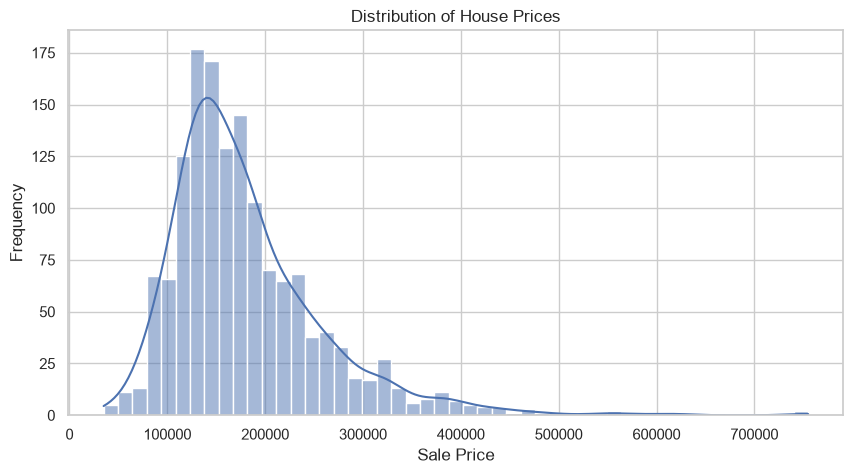

In [9]:

plt.figure(figsize=(10, 5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()


### Boxplot of Sale Price

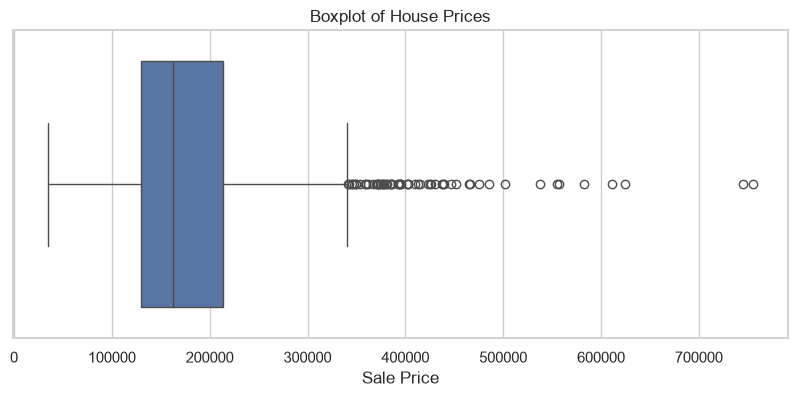

In [10]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")

plt.show()


### Log Transformation

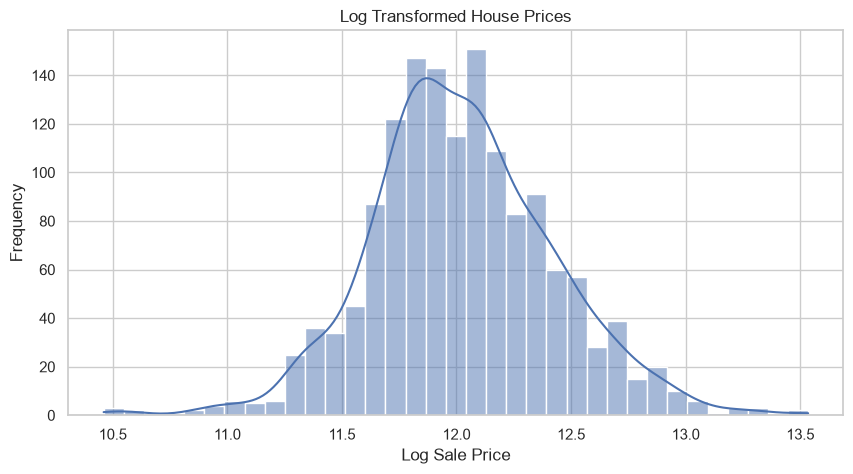

Original Skewness: 1.8828757597682129
Log Skewness: 0.12134661989685329


In [11]:

plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(df["SalePrice"]), kde=True)

plt.title("Log Transformed House Prices")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")

plt.show()

print("Original Skewness:", df["SalePrice"].skew())
print("Log Skewness:", np.log1p(df["SalePrice"]).skew())


### House Quality vs Price

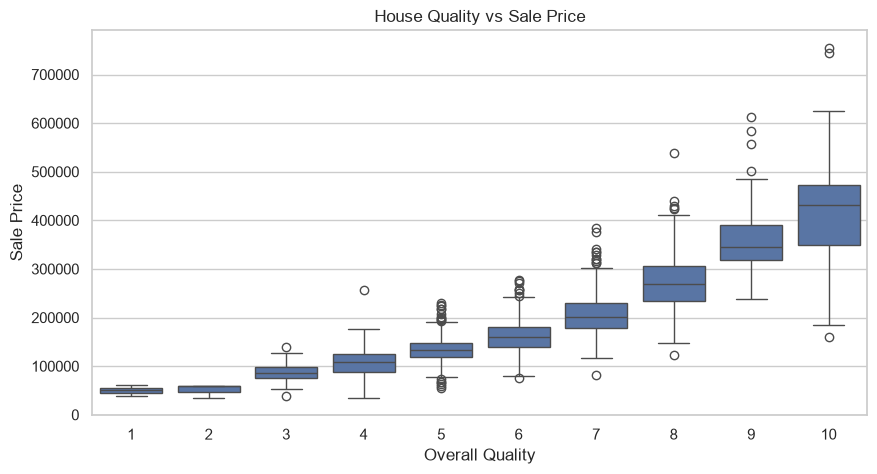

In [12]:

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="OverallQual", y="SalePrice")

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()


### Neighborhood vs Price

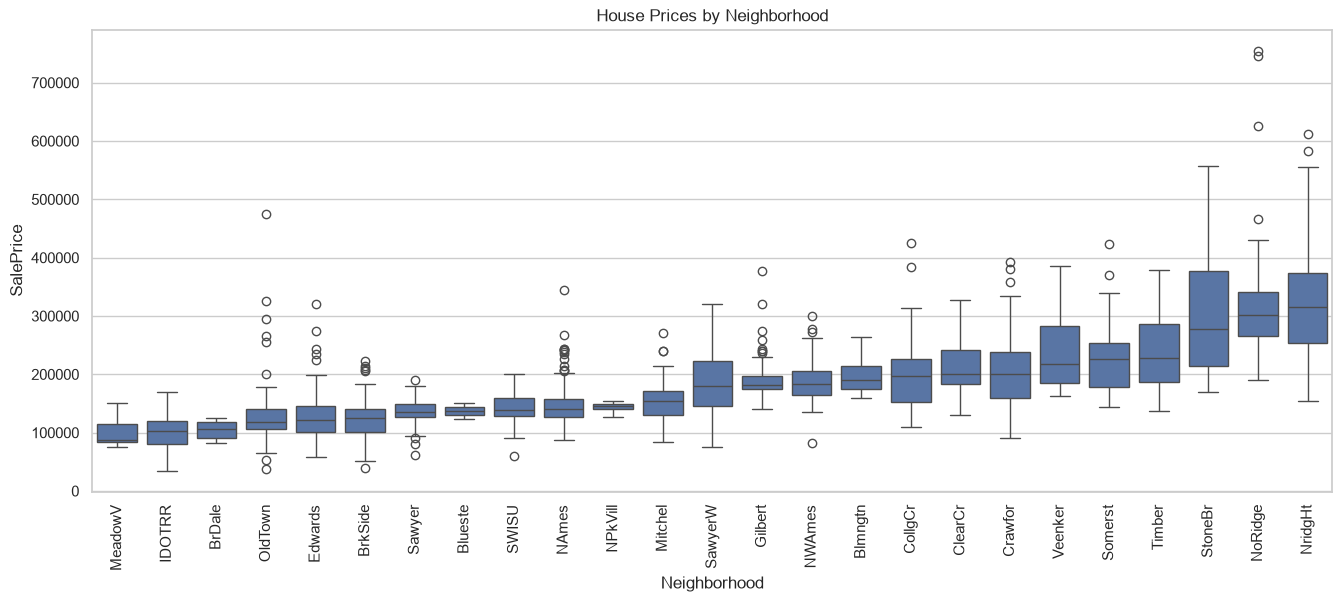

In [13]:

plt.figure(figsize=(16, 6))

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice",
    order=order
)

plt.title("House Prices by Neighborhood")
plt.xticks(rotation=90)

plt.show()


### Countplots

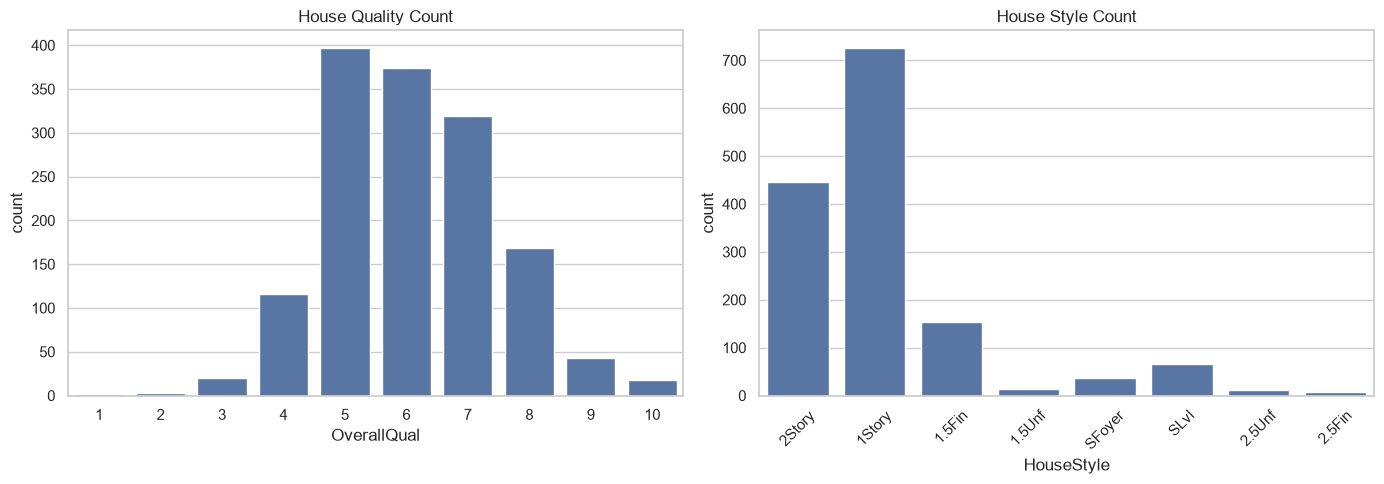

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="OverallQual", ax=axes[0])
axes[0].set_title("House Quality Count")

sns.countplot(data=df, x="HouseStyle", ax=axes[1])
axes[1].set_title("House Style Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



### Observation

1. House prices show a right-skewed distribution.
2. Log transformation helps reduce the skewness.
3. Higher-quality houses generally have higher prices.
4. House prices vary across neighborhoods.
5. Boxplots help identify unusual house prices.
6. Countplots show the frequency of different house qualities
   and house styles.



## 5. Correlation and Covariance

Correlation and covariance are statistical methods
used to understand the relationship between variables.

Correlation measures the strength and direction
of the relationship between two variables.

Covariance shows how two variables change together.

In this section, we will:
- Calculate the covariance matrix.
- Calculate the Pearson correlation matrix.
- Find the top 10 features correlated with SalePrice.
- Compare correlation and covariance.


### Covariance matrix

In [15]:

numeric_df = df.select_dtypes(include=np.number)

# Calculate covariance
cov_matrix = numeric_df.cov()

print("Covariance Matrix:")
cov_matrix


Covariance Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


In [16]:

# Calculate Pearson correlation
corr_matrix = numeric_df.corr(method="pearson")

print("Correlation Matrix:")
corr_matrix


Correlation Matrix:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


#### Top 10 correlated features

In [17]:
# Finding the top 10 features correlated with SalePrice
top_corr = corr_matrix["SalePrice"].drop(
    "SalePrice"
).abs().sort_values(ascending=False)

print("Top 10 Features Correlated with SalePrice:")
print(top_corr.head(10))

Top 10 Features Correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


#### Compare covariance and correlation

In [18]:
# Select top 3 features
top3 = top_corr.head(3).index

for col in top3:
    print("\nFeature:", col)

    print(
        "Covariance with SalePrice:",
        cov_matrix.loc[col, "SalePrice"]
    )

    print(
        "Correlation with SalePrice:",
        corr_matrix.loc[col, "SalePrice"]
    )


Feature: OverallQual
Covariance with SalePrice: 86904.12583679946
Correlation with SalePrice: 0.7909816005838054

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236586
Correlation with SalePrice: 0.7086244776126518

Feature: GarageCars
Covariance with SalePrice: 38020.18135897173
Correlation with SalePrice: 0.6404091972583521



### Interpretation

1. Correlation shows the strength and direction
   of relationships between variables.
2. Positive correlation means both variables
   generally increase together.
3. Negative correlation means one variable
   generally decreases when the other increases.
4. Covariance depends on the measurement scale.
5. Correlation is easier to compare because
   its values range from -1 to +1.

Correlation does not mean causation.
For example, GarageArea and GarageCars may be
strongly related because larger garages can
accommodate more cars.



## 6. Scatter Plots and Pair Plots

Scatter plots help us understand the relationship
between two numerical variables.

Pair plots display relationships between multiple
numerical variables in one figure.

In this section, we analyse:
- GrLivArea vs SalePrice
- TotalBsmtSF vs SalePrice
- YearBuilt vs SalePrice
- Pair plot of selected numerical features


#### Living area vs Sale price

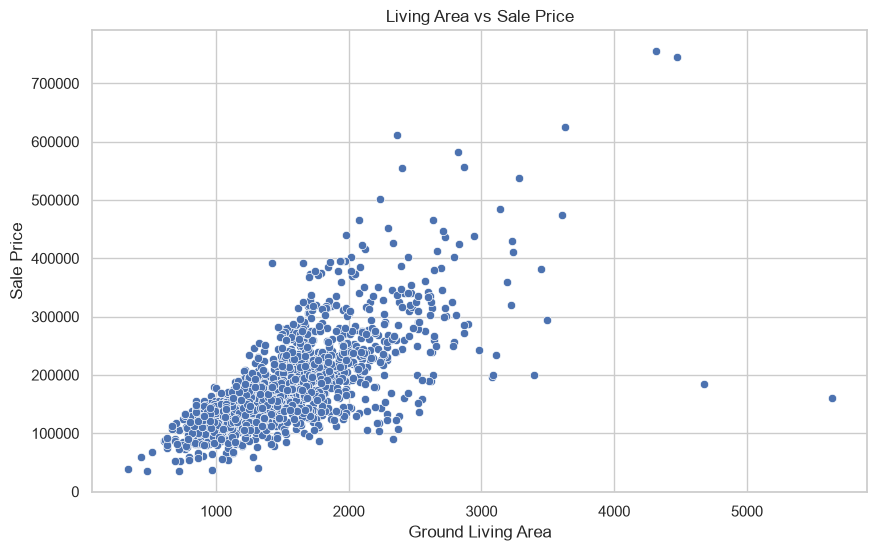

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Ground Living Area")
plt.ylabel("Sale Price")

plt.show()

#### Basement area vs Sale price 

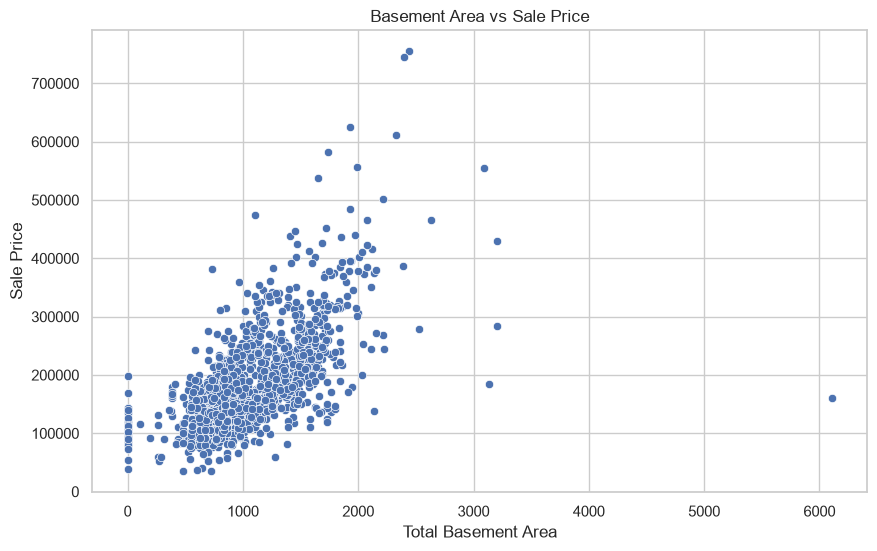

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice"
)

plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")

plt.show()

#### Year built vs Sale price

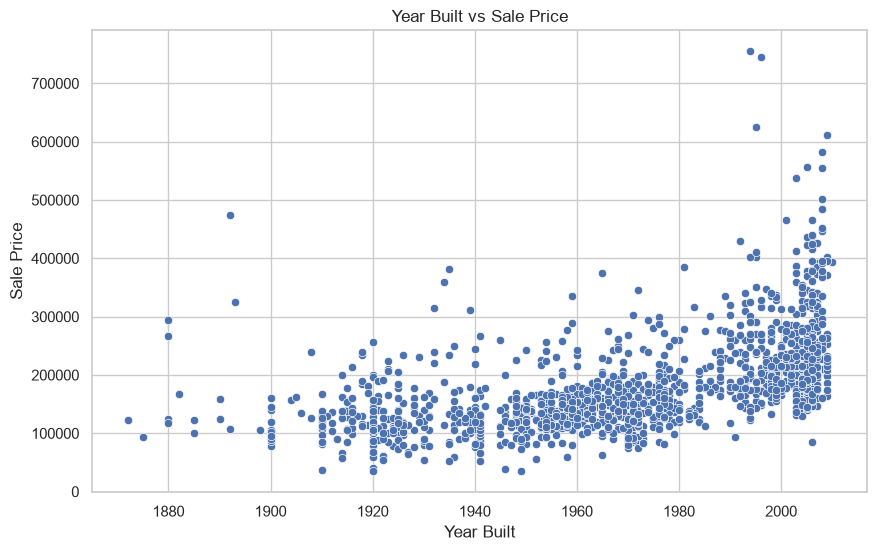

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice"
)

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()

#### Pair plot

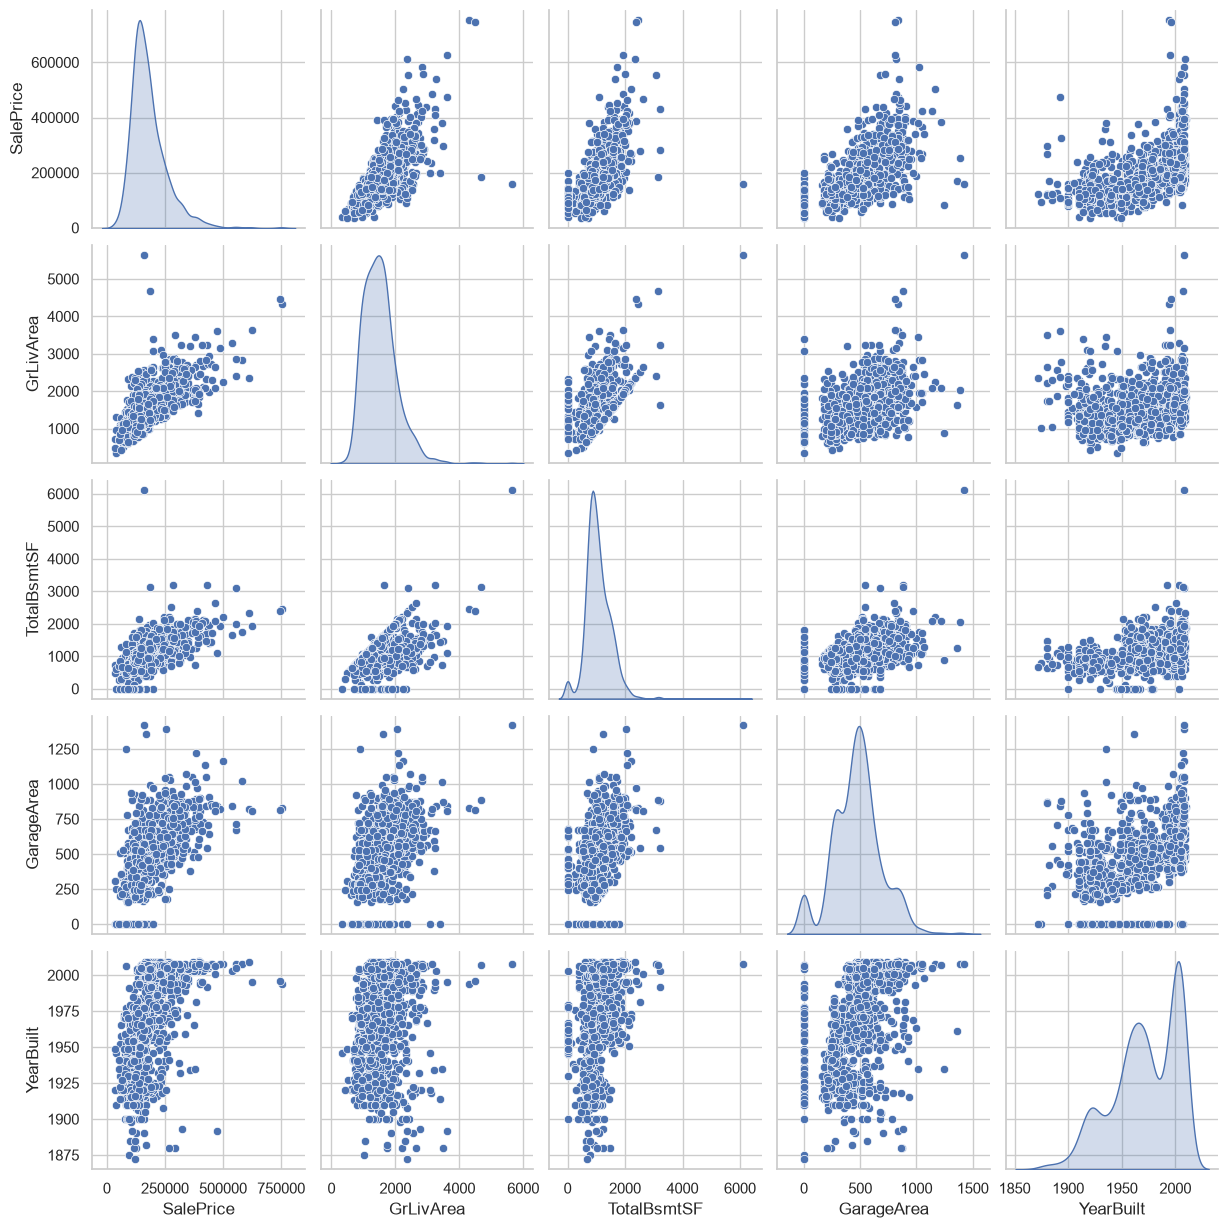

In [22]:
selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected],
    diag_kind="kde"
)

plt.show()


### Observation

1. Larger living areas generally have higher sale prices.
2. Basement area also shows a relationship with price.
3. Newer houses may have higher selling prices.
4. Pair plots help compare multiple numerical features.
5. Some unusual points can be observed in scatter plots.



## 7. Correlation Heatmap

A correlation heatmap is a graphical representation
of relationships between numerical variables.

It uses different colours to show positive and
negative correlations.

We will create a heatmap using the top 10 features
correlated with SalePrice.


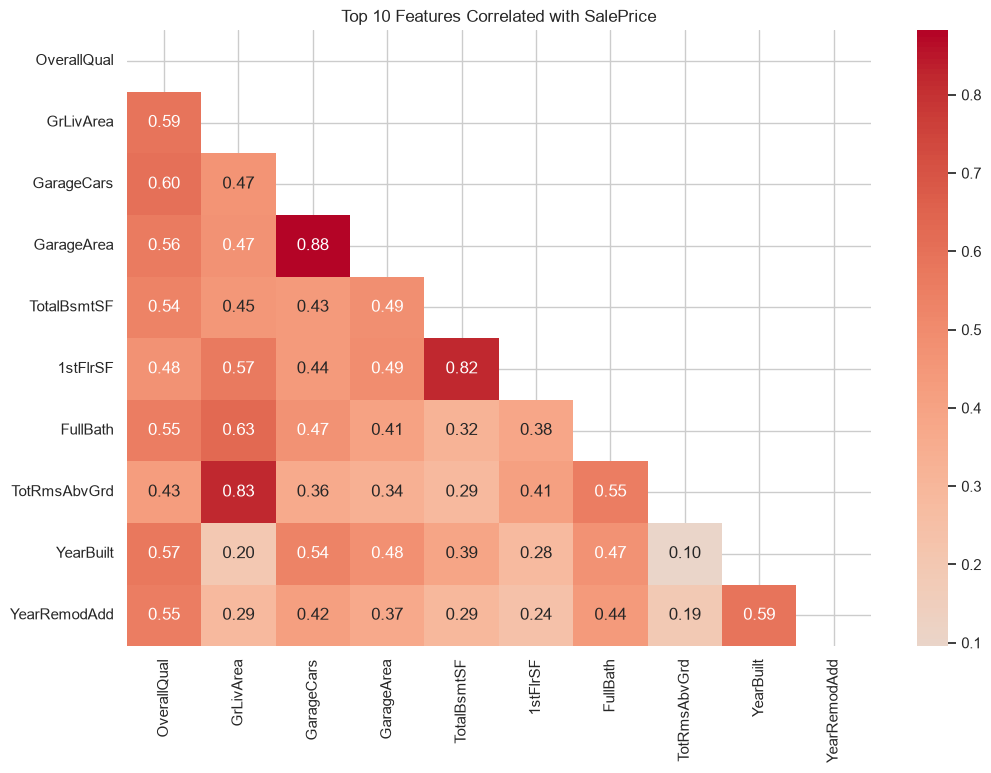

In [23]:
# Select top 10 correlated features
top10_features = top_corr.head(10).index.tolist()

# Calculate correlation
corr_top = df[top10_features].corr()

# Create upper triangle mask
mask = np.triu(
    np.ones_like(corr_top, dtype=bool)
)

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.show()


### Observation

The heatmap displays relationships between
the top 10 features.

Positive values indicate positive relationships.
Negative values indicate negative relationships.

Features with stronger correlations may be
important for understanding house prices.

However, correlation does not prove causation.


## 8. Outlier Detection

Outliers are values that are very different from most values in a dataset.

In this step, we use two methods:
1. IQR Method
2. Z-score Method

We will detect outliers in GrLivArea and SalePrice and compare the results.

#### IQR method

In [24]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)].index


def zscore_outliers(series, threshold=3):
    clean = series.dropna()
    z = pd.Series(stats.zscore(clean), index=clean.index)

    return z[abs(z) > threshold].index

Now comparing both methods

In [25]:
for column in ["GrLivArea", "SalePrice"]:

    iqr_result = iqr_outliers(df[column])
    z_result = zscore_outliers(df[column])

    print("\nColumn:", column)
    print("IQR Outliers:", len(iqr_result))
    print("Z-score Outliers:", len(z_result))
    print("Common Outliers:", len(set(iqr_result) & set(z_result)))


Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Common Outliers: 22


### Boxplots

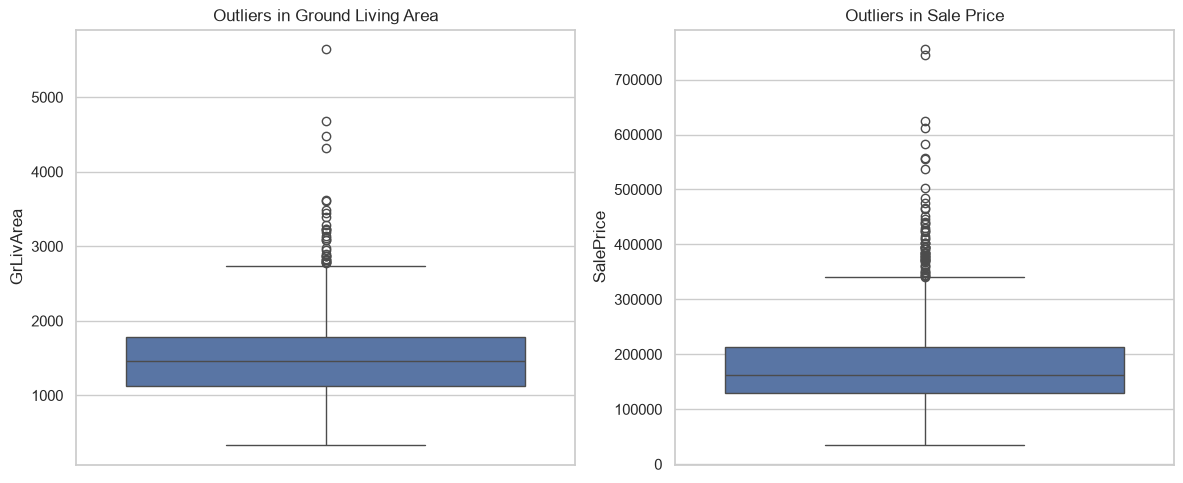

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["GrLivArea"])
plt.title("Outliers in Ground Living Area")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["SalePrice"])
plt.title("Outliers in Sale Price")

plt.tight_layout()
plt.show()

#### Highlight unusual houses

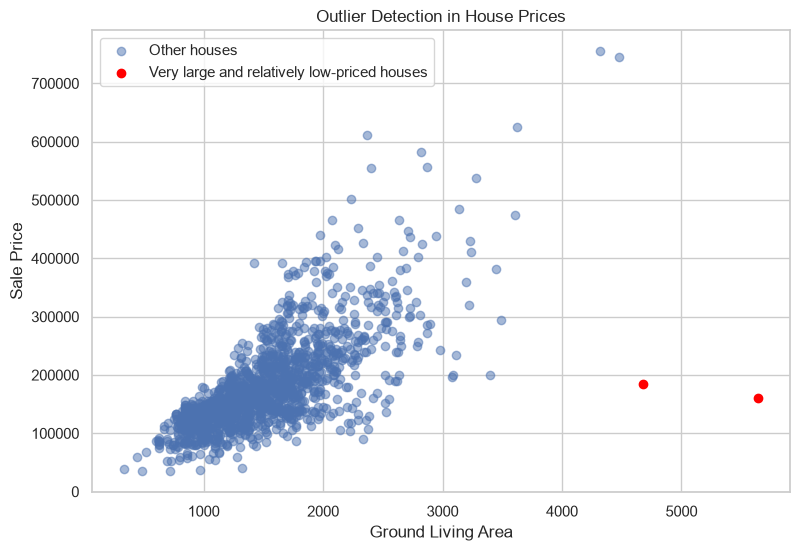

In [27]:
plt.figure(figsize=(9, 6))

normal = (df["GrLivArea"] <= 4000) | (df["SalePrice"] >= 300000)

plt.scatter(
    df.loc[normal, "GrLivArea"],
    df.loc[normal, "SalePrice"],
    label="Other houses",
    alpha=0.5
)

plt.scatter(
    df.loc[~normal, "GrLivArea"],
    df.loc[~normal, "SalePrice"],
    color="red",
    label="Very large and relatively low-priced houses"
)

plt.xlabel("Ground Living Area")
plt.ylabel("Sale Price")
plt.title("Outlier Detection in House Prices")
plt.legend()
plt.show()

### Interpretation

The IQR method identifies values outside the lower and upper quartile limits. The Z-score method identifies values that are more than 3 standard deviations from the mean.

The IQR method can detect more outliers when data is skewed because it uses quartiles instead of the mean and standard deviation.

Outliers should not be removed automatically. Some expensive or unusually large houses may be genuine sales.

## 9. Data Quality Checks

In this step, we check the quality of our dataset.

We will:
1. Find duplicate rows.
2. Check categorical values for extra spaces.
3. Handle missing values.
4. Check impossible values such as YearBuilt greater than YrSold.

In [28]:
print("Duplicate rows:", df.duplicated().sum())

df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows: 0
Shape after removing duplicates: (1460, 81)


#### Checking categorical columns

In [29]:
categorical_columns = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df_clean[column].unique()[:15])

for column in categorical_columns:
    df_clean[column] = df_clean[column].astype("object").str.strip()


Column: MSZoning
<ArrowStringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str

Column: Street
<ArrowStringArray>
['Pave', 'Grvl']
Length: 2, dtype: str

Column: Alley
<ArrowStringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str

Column: LotShape
<ArrowStringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str

Column: LandContour
<ArrowStringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str

Column: Utilities
<ArrowStringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str

Column: LotConfig
<ArrowStringArray>
['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']
Length: 5, dtype: str

Column: LandSlope
<ArrowStringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str

Column: Neighborhood
<ArrowStringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV']
Length: 15, dtype: str

Column: Condition1
<ArrowStringArray>
['Norm', 'Feedr', 'PosN', 'Artery'

/var/folders/cd/fzx44ws521v5b6bbqjv6t5080000gn/T/ipykernel_2864/381196369.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(


### Handle missing values

In [30]:
# Columns absent
absent_columns = [
    "PoolQC",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType"
]

for column in absent_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna("None")


# Fill LotFrontage using neighborhood median
df_clean["LotFrontage"] = df_clean.groupby(
    "Neighborhood"
)["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(
    df_clean["LotFrontage"].median()
)


# Fill remaining numerical missing values with median
numeric_columns = df_clean.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )


# Filling categorical missing values with Unknown
categorical_columns = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

#### Verify missing values

In [31]:
print("Remaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nDataset Shape:", df_clean.shape)

Remaining missing values:
0

Dataset Shape: (1460, 81)


#### Check impossible values

In [32]:
print(
    "YearBuilt greater than YrSold:",
    (df_clean["YearBuilt"] > df_clean["YrSold"]).sum()
)

area_columns = [
    "GrLivArea",
    "TotalBsmtSF",
    "LotArea",
    "GarageArea"
]

for column in area_columns:
    print(
        column,
        "Negative values:",
        (df_clean[column] < 0).sum()
    )

YearBuilt greater than YrSold: 0
GrLivArea Negative values: 0
TotalBsmtSF Negative values: 0
LotArea Negative values: 0
GarageArea Negative values: 0


### Interpretation

We checked the dataset for duplicate rows, inconsistent category labels, missing values, and impossible values.

Missing values that represent an absent house feature were filled with "None". Numerical missing values were filled using the median, and remaining categorical missing values were labelled "Unknown".

We kept the original dataset unchanged and performed these checks on a separate cleaned dataset.

## 10. Final EDA Dashboard

The final dashboard combines four visualizations:

1. Average Sale Price by Year Built.
2. Top 10 Neighborhoods by Average Sale Price.
3. Sale Price Distribution with Mean and Median.
4. Ground Living Area vs Sale Price, coloured by Overall Quality.

Now, Creating EDA Dashboard

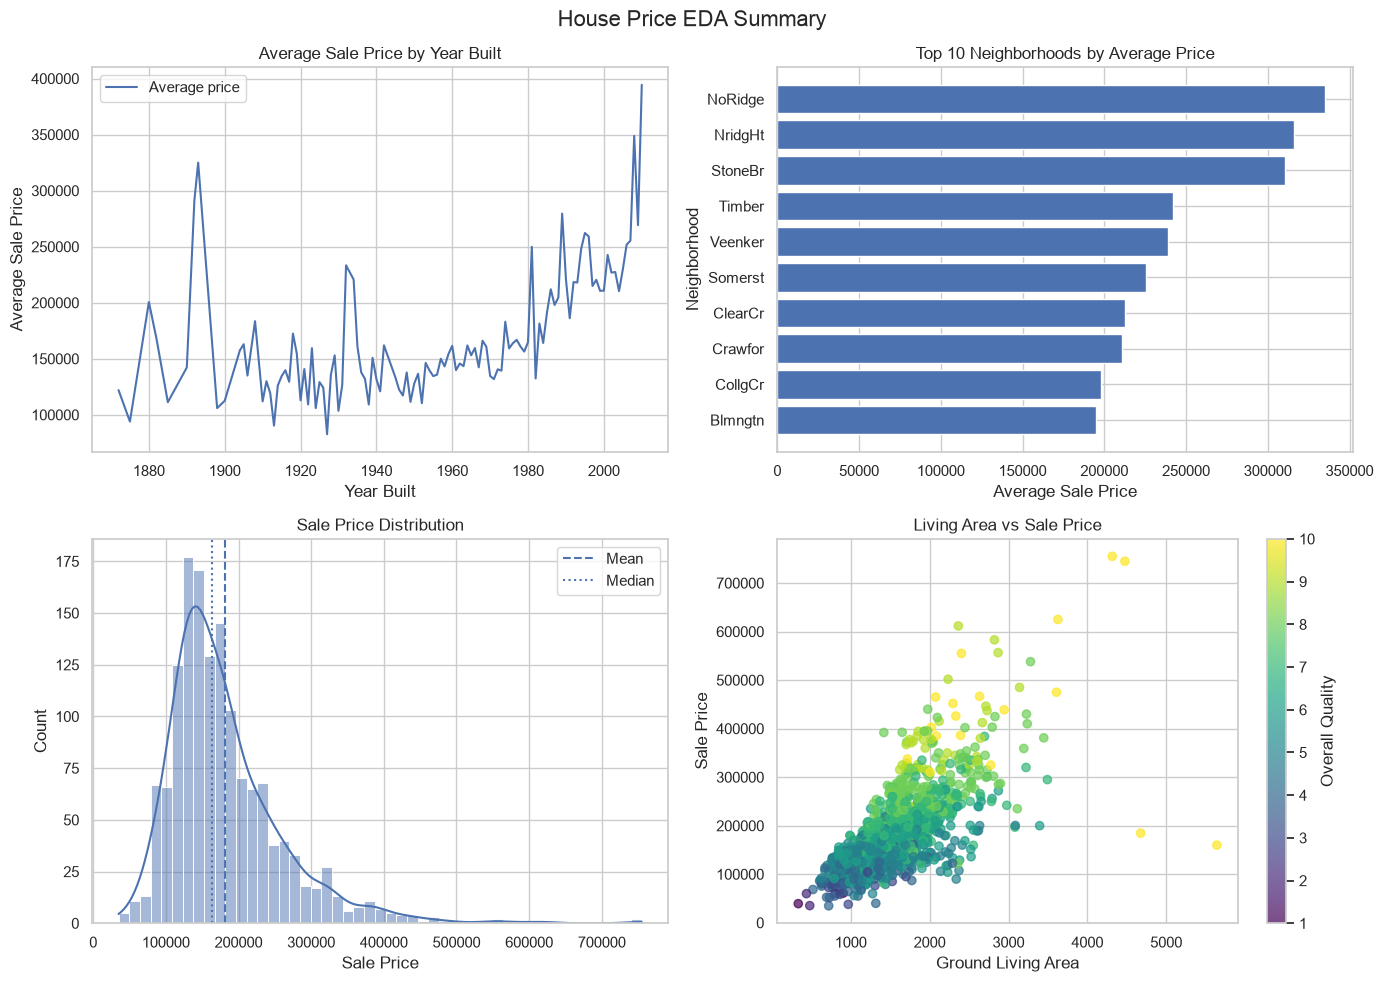

Dashboard saved successfully!


In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Average Sale Price by Year Built
year_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    year_price.index,
    year_price.values,
    label="Average price"
)

axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()


# Panel 2: Top 10 Neighborhoods
neighborhood_price = (
    df_clean.groupby("Neighborhood")["SalePrice"]
    .mean()
    .nlargest(10)
    .sort_values()
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")


# Panel 3: Sale Price Distribution
sns.histplot(
    df_clean["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

mean_price = df_clean["SalePrice"].mean()
median_price = df_clean["SalePrice"].median()

axes[1, 0].axvline(
    mean_price,
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    median_price,
    linestyle=":",
    label="Median"
)

axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].legend()


# Panel 4: Living Area vs Sale Price
scatter = axes[1, 1].scatter(
    df_clean["GrLivArea"],
    df_clean["SalePrice"],
    c=df_clean["OverallQual"],
    cmap="viridis",
    alpha=0.7
)

axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Ground Living Area")
axes[1, 1].set_ylabel("Sale Price")

fig.colorbar(
    scatter,
    ax=axes[1, 1],
    label="Overall Quality"
)


# Main title and layout
fig.suptitle("House Price EDA Summary", fontsize=16)

plt.tight_layout()

# Save dashboard
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()

print("Dashboard saved successfully!")

## Conclusion

In this project, we performed Exploratory Data Analysis on the Ames Housing Dataset.

We studied:
- Dataset structure and variable types.
- Descriptive statistics and distributions.
- Correlation and covariance.
- Scatter plots and correlation heatmap.
- Outlier detection using IQR and Z-score.
- Missing values and data quality.
- Final EDA dashboard.

The analysis helped us understand how house features, quality, living area, and neighborhood are related to house sale prices.

This project uses Exploratory Data Analysis only. No Machine Learning model was developed.